# Supplementary Figure S14: variance inflation factor of the idea diffusion model

It reads its input from the data folder (`path2data`). The figures are saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

In [2]:
namedict = {'const':'Intercept',
            'Pop_o':'log Population origin', 'Pop_d':'log Population destination',
            'GDP_o':'log GDP Origin', 'GDP_d':'log GDP destination',
            'GDP_PCAP_o':'log GDP per capita origin', 'GDP_PCAP_d':'log GDP per capita destination',
            'Norigin':'Number of ideas origin', 'Ntarget':'Number of ideas destination',
            'tradeflow_baci':'log Tradeflow', 'FieldDistance':'Topic distance',
            "dist":'log Physical distance', "comlang_off":"Common language",
            "NormNcites":"Fraction of Citations to Origin",
           "SameComm":'Same Community',
           "NumPub_o":'log num. of pub. origin',
           "NumPub_d":'log number of pub. destination',
           'Pedge':'Positive citation preference', 'Nedge':'Negative citation preference', 
            'pr_o':'Network centrality origin', 'pr_d':'Network centrality destination'}


In [3]:
panel_data = pd.read_csv(os.path.join(path2data, 'diffusion_panel_data_1990_2017.csv.gz'))
network_features = [ 'Pedge', 'Nedge'] 
#network_features = [ 'Pedge', 'Nedge', 'SameComm'] 
#network_features = [ 'Pedge', 'Nedge',  'pr_o', 'pr_d'] 
network_features = [ 'Pedge', 'Nedge', 'SameComm', 'pr_o', 'pr_d'] 

Model_features = [
#'Pop_o','Pop_d', 
'GDP_PCAP_o','GDP_PCAP_d',
'NumPub_o','NumPub_d', 
'NormNcites',  
'FieldDistance', 
'dist', 
'comlang_off'
] + network_features


X = panel_data[Model_features + [ 'Norigin', 'Fideas']].dropna().copy()
Y = X['Fideas']
freq_weights = X['Norigin'].values
X = sm.add_constant(X[Model_features])

for c in Model_features:
    if X[c].nunique() > 2:
        X[c] = (X[c] - X[c].mean())/X[c].std()

vif_df = pd.DataFrame()
vif_df["Variable"] = X.columns
vif_df["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

vif_df['Variable']=vif_df['Variable'].replace(namedict)

#model=sm.GLM(Y, X, family=sm.families.Binomial(sm.families.links.logit())).fit()
model=sm.GLM(Y, X, family=sm.families.Binomial(sm.families.links.logit()), freq_weights=freq_weights).fit()

predictions = model.predict(X) 
print(model.pseudo_rsquared(kind='mcf'))
params = model.params
conf = model.conf_int()
conf['Odds Ratio'] = params
conf.columns = ['5%', '95%', 'Odds Ratio']
print(np.exp(conf))

model.summary()

0.4248119341799661
                     5%       95%  Odds Ratio
const          0.254320  0.262404    0.258330
GDP_PCAP_o     1.319744  1.343300    1.331470
GDP_PCAP_d     1.083653  1.093667    1.088649
NumPub_o       0.730610  0.746141    0.738335
NumPub_d       4.741752  4.796227    4.768912
NormNcites     1.054395  1.058477    1.056434
FieldDistance  0.714497  0.721512    0.717996
dist           1.010699  1.019164    1.014923
comlang_off    0.989790  1.010325    1.000005
Pedge          1.126826  1.155277    1.140963
Nedge          0.952675  0.969649    0.961125
SameComm       1.071280  1.095541    1.083343
pr_o           1.007300  1.015541    1.011412
pr_d           1.039934  1.048757    1.044336


/Users/psp2nq/anaconda3/lib/python3.11/site-packages/statsmodels/genmod/families/links.py:13: FutureWarning: The logit link alias is deprecated. Use Logit instead. The logit link alias will be removed after the 0.15.0 release.
  warnings.warn(


<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                 Fideas   No. Observations:                12032
Model:                            GLM   Df Residuals:                  2814066
Model Family:                Binomial   Df Model:                           13
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.9875e+05
Date:                Tue, 03 Nov 2026   Deviance:                       39890.
Time:                        18:26:04   Pearson chi2:                 4.34e+04
No. Iterations:                     6   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -1.3535      0.008   -169.549      0.000      -1.369      -1.338
GDP_PCAP_o        0.2863      0.005     63.434      0.000       0.277       0.295
GDP_PCAP_d        0.0849      0.002     36.196      0.000       0.080       0.090
NumPub_o         -0.3034      0.005    -56.533      0.000      -0.314      -0.293
NumPub_d          1.5621      0.003    536.070      0.000       1.556       1.568
NormNcites        0.0549      0.001     55.694      0.000       0.053       0.057
FieldDistance    -0.3313      0.002   -132.926      0.000      -0.336      -0.326
dist              0.0148      0.002      6.962      0.000       0.011       0.019
comlang_off    5.065e-06      0.005      0.001      0.999      -0.010       0.010
Pedge             0.1319      0.006     20.730      0.000       0.119       0.144
Nedge            -0.0397      0.005     -8.801      0.000      -0.048      -0.031
SameComm          0.0801      0.006     14.012      0.000       0.069       0.091
pr_o              0.0113      0.002      5.459      0.000       0.007       0.015
pr_d              0.0434      0.002     20.130      0.000       0.039       0.048
=================================================================================
"""

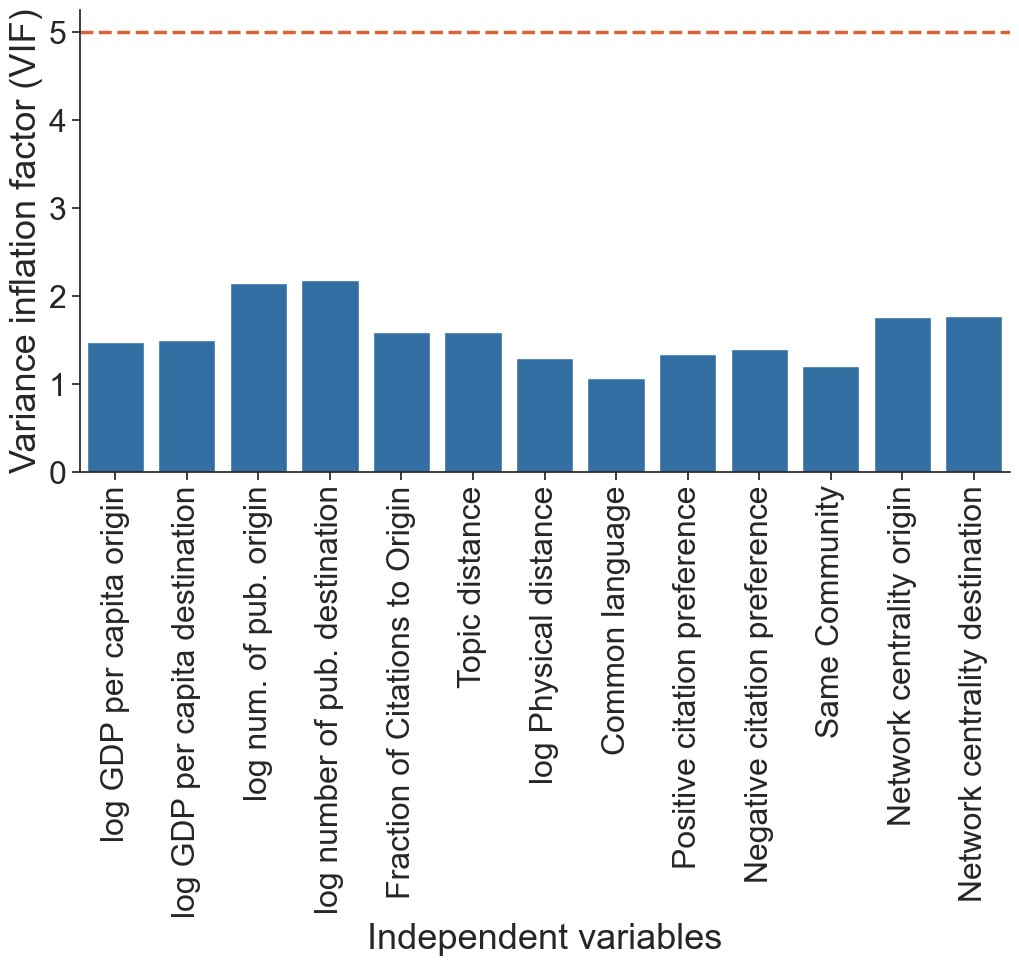

In [4]:
colours=['#8D95A0','#2171b5','#DA6437']

custom_params = {"axes.spines.bottom": True, "axes.spines.right": False, "axes.spines.top": False,
                     "axes.spines.left": True,"ytick.left":True, "xtick.bottom":True}
sns.set_theme(style='ticks', rc=custom_params)


plt.figure(figsize=(12, 6))

vif_plot=vif_df[vif_df['Variable']!='Intercept']

ax = sns.barplot(x="Variable", y="VIF", data=vif_plot, 
                     color=colours[1])
    
plt.xlabel("Independent variables", fontsize=26)
plt.ylabel("Variance inflation factor (VIF)", fontsize=26)

plt.xticks(rotation=90, ha='center')

ax.axhline(y=5, color=colours[2],  linestyle='--', lw=2.5)


ax.tick_params(axis='both', which='major', labelsize=23, direction='out',)

#ax.set_ylim([0,3])

plt.savefig(os.path.join(path2figures, 'FigSI_vif_diffusion.pdf'), bbox_inches='tight')

plt.show()

## Source Data for Supplementary Fig. S14

The values plotted, written to `Source Data/SourceData_FigS14.xlsx`.

In [5]:
from sourcedatautils import write_source_data

write_source_data('SourceData_FigS14.xlsx', 'Supplementary Figure 14: Variance inflation factor of the idea diffusion model.',
                  'Variance inflation factor (VIF) of each independent variable of the logistic regression model of idea diffusion.',
                  [('S14', 'VIF of each independent variable.', vif_plot)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS14.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
